
=== f1(x) = x^3 + 2x + 1 (3 points) ===
Erreur Lagrange = 0.38490008995449365
Erreur Newton   = 0.38490008995449365
Erreur Hermite  = 1.3322676295501878e-15


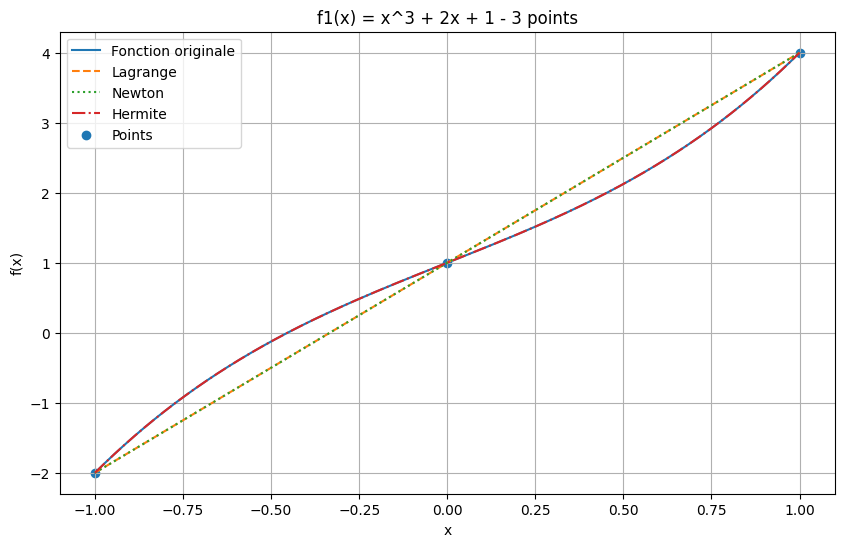


=== f2(x) = 1/(1 + 10x^2) (3 points) ===
Erreur Lagrange = 0.487886329908592
Erreur Newton   = 0.487886329908592
Erreur Hermite  = 0.35885881343979975


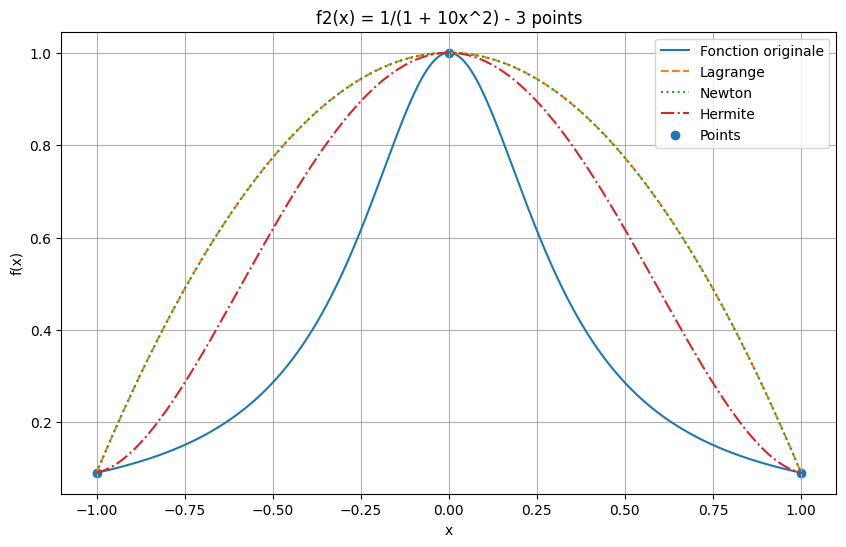


=== f1(x) = x^3 + 2x + 1 (5 points) ===
Erreur Lagrange = 8.881784197001252e-16
Erreur Newton   = 8.881784197001252e-16
Erreur Hermite  = 2.220446049250313e-15


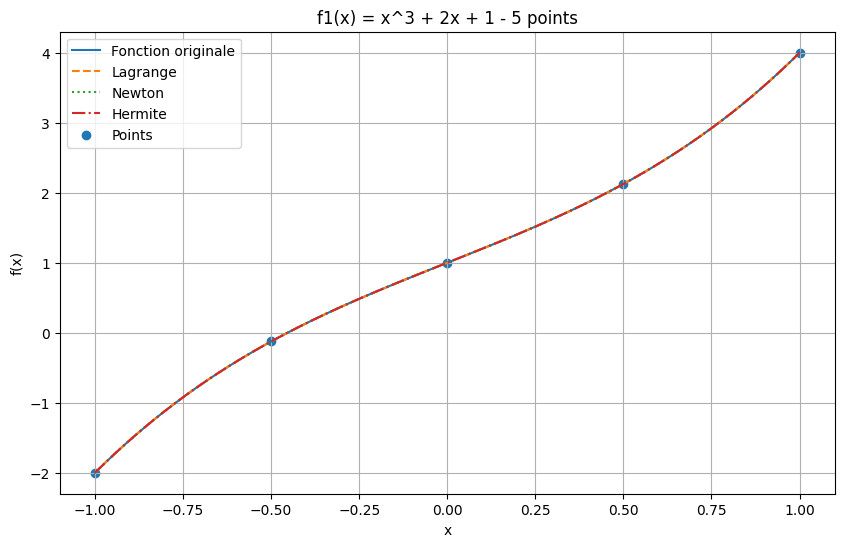


=== f2(x) = 1/(1 + 10x^2) (5 points) ===
Erreur Lagrange = 0.31539488950033223
Erreur Newton   = 0.3153948895003321
Erreur Hermite  = 0.11510809961838514


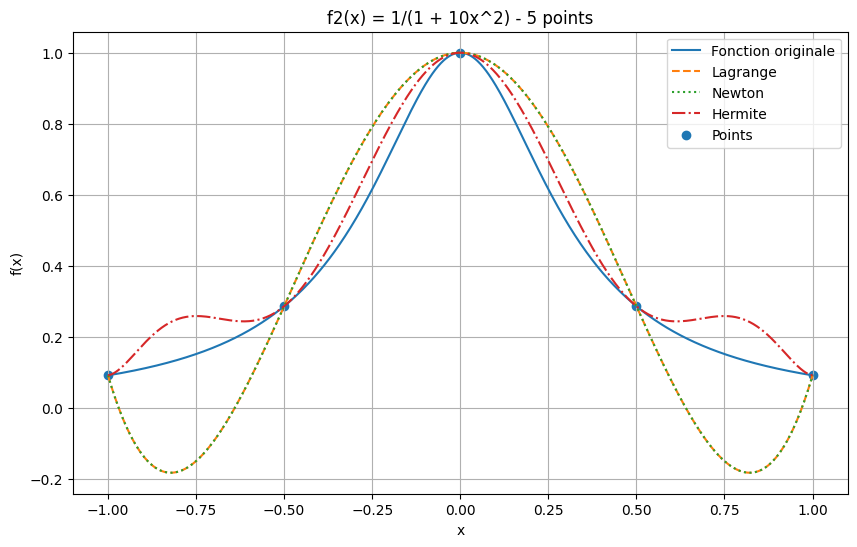


=== f1(x) = x^3 + 2x + 1 (9 points) ===
Erreur Lagrange = 2.6645352591003757e-15
Erreur Newton   = 1.3322676295501878e-15
Erreur Hermite  = 2.220446049250313e-15


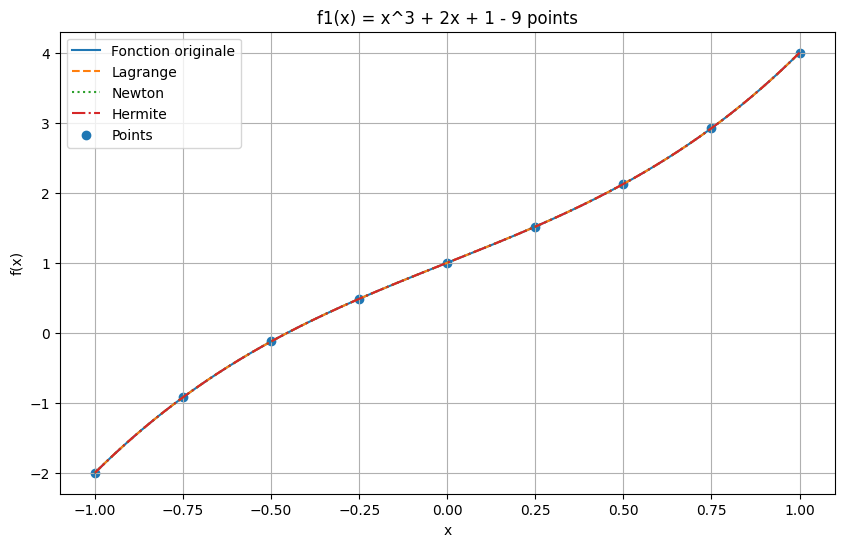


=== f2(x) = 1/(1 + 10x^2) (9 points) ===
Erreur Lagrange = 0.4398958506657562
Erreur Newton   = 0.43989585066576636
Erreur Hermite  = 0.2163748588595869


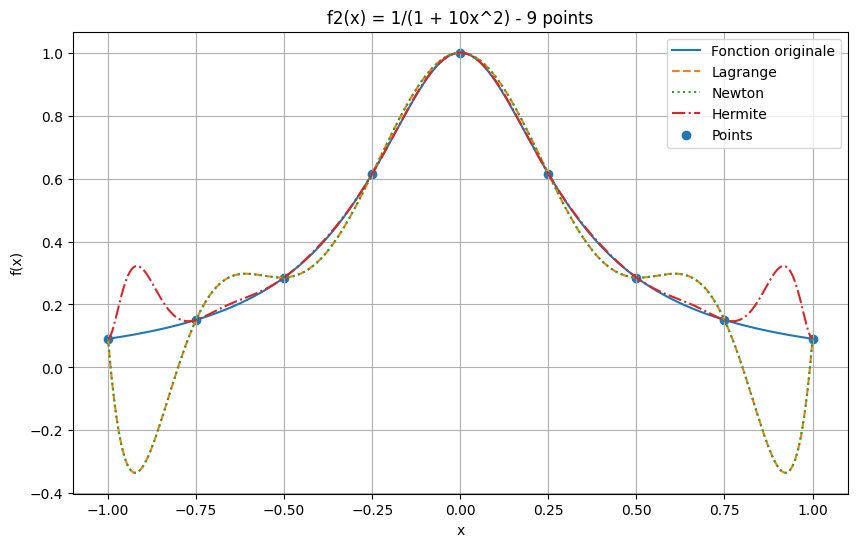


=== f1(x) = x^3 + 2x + 1 (17 points) ===
Erreur Lagrange = 2.2581936320875684e-13
Erreur Newton   = 1.7763568394002505e-15
Erreur Hermite  = 2.220446049250313e-15


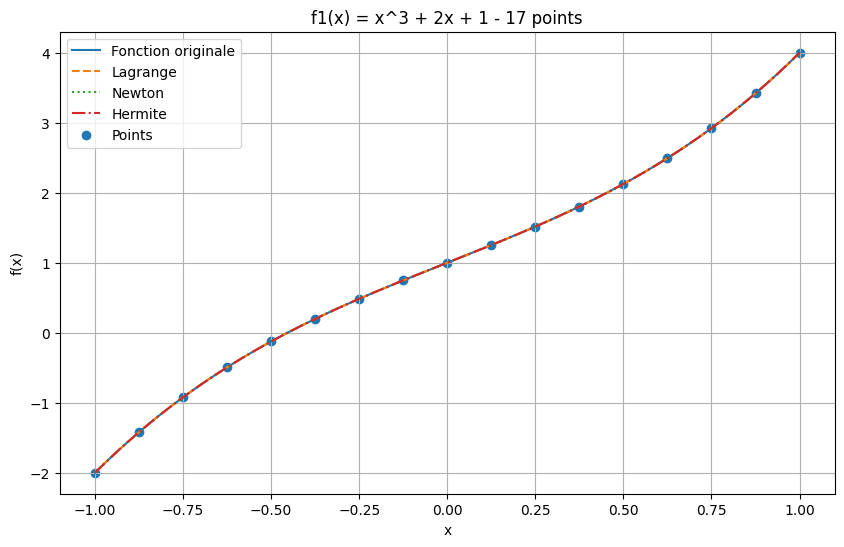


=== f2(x) = 1/(1 + 10x^2) (17 points) ===
Erreur Lagrange = 1.7967937052265892
Erreur Newton   = 1.796793705226852
Erreur Hermite  = 3.5730352391622686


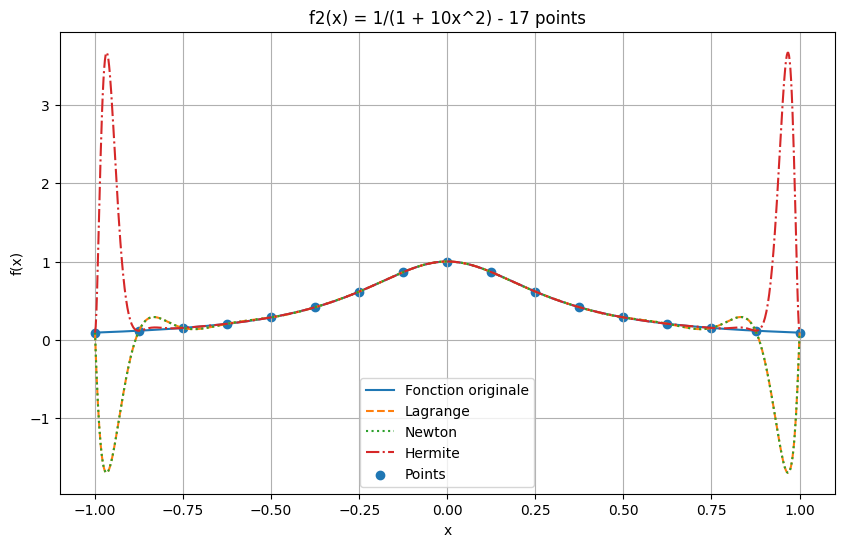

In [3]:
import numpy as np
import matplotlib.pyplot as plt


# Les deux fonctions à interpoler
def f1(x):
    return x**3 + 2*x + 1

def df1(x):
    return 3*x**2 + 2

# Fonction de Runge
def f2(x):
    return 1 / (1 + 10*x**2)

def df2(x):
    return -20*x / (1 + 10*x**2)**2


# ---------- Lagrange ----------
def lagrange(xs, ys, x):
    n = len(xs)
    P = 0
    for i in range(n):
        L = 1
        for j in range(n):
            if i != j:
                L *= (x - xs[j]) / (xs[i] - xs[j])
        P += ys[i] * L
    return P


# ---------- Newton ----------
def diff_divisees(xs, ys):
    n = len(xs)
    T = np.zeros((n, n))
    T[:, 0] = ys
    for j in range(1, n):
        for i in range(n - j):
            T[i, j] = (T[i+1, j-1] - T[i, j-1]) / (xs[i+j] - xs[i])
    return T

def newton(xs, ys, x):
    T = diff_divisees(xs, ys)
    P = T[0, 0]
    prod = 1
    for i in range(1, len(xs)):
        prod *= x - xs[i-1]
        P += T[0, i] * prod
    return P


# ---------- Hermite ----------
def hermite(xs, ys, dys):
    n = len(xs)
    m = 2 * n
    z = np.zeros(m)
    Q = np.zeros((m, m))

    # chaque point est répété deux fois
    for i in range(n):
        z[2*i] = z[2*i+1] = xs[i]
        Q[2*i, 0] = Q[2*i+1, 0] = ys[i]

    # colonne 1 : dérivée si le point est répété, sinon pente classique
    for i in range(m - 1):
        if z[i] == z[i+1]:
            Q[i, 1] = dys[i // 2]
        else:
            Q[i, 1] = (Q[i+1, 0] - Q[i, 0]) / (z[i+1] - z[i])

    # le reste de la table
    for j in range(2, m):
        for i in range(m - j):
            Q[i, j] = (Q[i+1, j-1] - Q[i, j-1]) / (z[i+j] - z[i])

    return z, Q

def eval_hermite(xs, ys, dys, x):
    z, Q = hermite(xs, ys, dys)
    P = Q[0, 0]
    prod = 1
    for i in range(1, len(z)):
        prod *= x - z[i-1]
        P += Q[0, i] * prod
    return P


# ---------- Comparaison ----------
def comparaison(f, df, nom, n):
    # points équidistants sur [-1, 1]
    xs = np.linspace(-1, 1, n)
    ys = f(xs)
    dys = df(xs)

    # grille fine pour tracer
    x = np.linspace(-1, 1, 1000)
    y = f(x)

    y_L = np.array([lagrange(xs, ys, xi) for xi in x])
    y_N = np.array([newton(xs, ys, xi) for xi in x])
    y_H = np.array([eval_hermite(xs, ys, dys, xi) for xi in x])

    print(f"\n=== {nom} ({n} points) ===")
    print("Erreur Lagrange =", np.max(np.abs(y - y_L)))
    print("Erreur Newton   =", np.max(np.abs(y - y_N)))
    print("Erreur Hermite  =", np.max(np.abs(y - y_H)))

    plt.figure(figsize=(10, 6))
    plt.plot(x, y, label="Fonction originale")
    plt.plot(x, y_L, "--", label="Lagrange")
    plt.plot(x, y_N, ":", label="Newton")
    plt.plot(x, y_H, "-.", label="Hermite")
    plt.scatter(xs, ys, label="Points")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.title(f"{nom} - {n} points")
    plt.legend()
    plt.grid()
    plt.show()


# ---------- Expérience ----------
for n in [3, 5, 9, 17]:
    comparaison(f1, df1, "f1(x) = x^3 + 2x + 1", n)
    comparaison(f2, df2, "f2(x) = 1/(1 + 10x^2)", n)
